In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from kafe2 import XYFit
from pathlib import Path
import locale
import yaml

In [ ]:
from setup import (
    black,
    colors,
    plot_style,
    configuration,
    rise_time,
)
from processing import (
    cm2inch,
)

In [ ]:
locale.setlocale(locale.LC_ALL, "en_US.UTF-8")

plt.style.use(plot_style)
plt.rcParams.update(
    {
        "font.size": 8,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "lines.linewidth": 0.7,
        "patch.linewidth": 0.7,
        "lines.markeredgewidth": 0.7,
        "lines.markersize": 3.5,
        "axes.formatter.use_locale": True,
    }
)

In [ ]:
configurations = ["t1", "t2"]

### Load dynamic characterization results

In [ ]:
results = []
metadata = []
for configuration in configurations:
    path = Path("results", f"dynamic-characterization-{configuration}")

    results.append(np.load(path.with_suffix(".npz")))
    metadata.append(yaml.safe_load(path.with_suffix(".yaml").read_text()))

number_configurations = len(configurations)

gases = tuple(metadata[0]["gases"])
number_gases = len(gases)
gas_labels = {"isopropanol": "iPrOH", "ethanol": "EtOH"}

spectral_resolutions = [
    float(metadata[jj]["spectral_resolution"]) for jj in range(number_configurations)
]
times_per_spectrum = [
    float(metadata[jj]["time_per_spectrum"]) for jj in range(number_configurations)
]

response_times = [results[jj]["response_times"] for jj in range(number_configurations)]
response_times_se = [
    results[jj]["response_times_se"] for jj in range(number_configurations)
]
limits_of_detection = [
    results[jj]["limits_of_detection"] for jj in range(number_configurations)
]
limits_of_detection_se = [
    results[jj]["limits_of_detection_se"] for jj in range(number_configurations)
]

factors = results[0]["factors"]
response_times_cstr = results[0]["response_times_cstr"]

time = [results[0][f"time_{ii}"] for ii in range(number_gases)]
concentration = [results[0][f"concentration_{ii}"] for ii in range(number_gases)]

cstr_time = [results[0][f"cstr_time_{ii}"] for ii in range(number_gases)]
cstr_concentration = [
    results[0][f"cstr_concentration_{ii}"] for ii in range(number_gases)
]
response_time_range = [
    results[0][f"response_time_range_{ii}"] for ii in range(number_gases)
]

### Fit limit of detection

In [ ]:
response_times_fit = [[] for jj in range(number_configurations)]
limits_of_detection_fit = [[] for jj in range(number_configurations)]
limits_of_detection_fit_se = [[] for jj in range(number_configurations)]


def limit_of_detection_model(filter_time, limit_of_detection_n1, time_per_spectrum):
    tau = filter_time[filter_time > 0] / np.log(9.0)

    limit_of_detection = np.zeros_like(filter_time)
    limit_of_detection[filter_time == 0] = limit_of_detection_n1
    limit_of_detection[filter_time > 0] = limit_of_detection_n1 * np.sqrt(
        np.tanh(time_per_spectrum / (2 * tau))
    )

    return limit_of_detection


filter_times = factors * rise_time

for jj in range(number_configurations):
    for ii in range(number_gases):
        fit = XYFit(
            xy_data=[factors * rise_time, limits_of_detection[jj][ii]],
            model_function=limit_of_detection_model,
        )
        fit.add_error(axis="y", err_val=limits_of_detection_se[jj][ii])

        fit.set_parameter_values(
            limit_of_detection_n1=np.max(limits_of_detection[jj][ii])
        )
        fit.limit_parameter("limit_of_detection_n1", lower=0)

        fit.fix_parameter("time_per_spectrum", times_per_spectrum[jj])

        fit.do_fit()

        filter_time_fit = np.linspace(
            np.min(factors * rise_time),
            np.max(factors * rise_time),
            1_001,
        )
        response_time_fit = interp1d(
            filter_times,
            response_times[jj][ii],
            bounds_error=False,
            fill_value="extrapolate",
        )(filter_time_fit)

        response_times_fit[jj].append(response_time_fit)
        limits_of_detection_fit[jj].append(fit.eval_model_function(x=filter_time_fit))

### Plot dynamic characterization

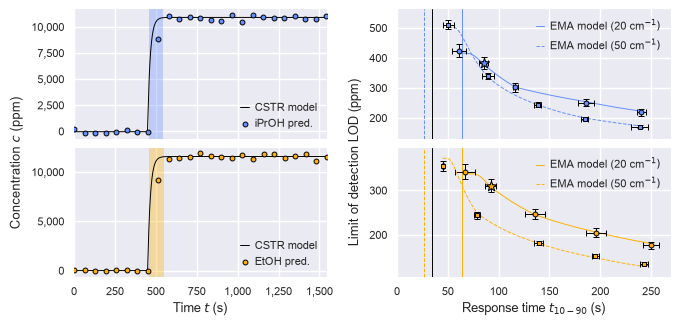

In [ ]:
fig = plt.figure(figsize=cm2inch((17, 8)), constrained_layout=True)
subfigs = fig.subfigures(1, 2, wspace=0.02)
axs = np.array([subfig.subplots(number_gases, 1, sharex=True) for subfig in subfigs]).T

markers = ["o", "s"]
linestyles = ["-", "--"]

for ii, gas in enumerate(gases):
    ### filtered step response ###
    axs[ii, 0].axvspan(
        *response_time_range[ii],
        facecolor=colors[ii] + "55",
        edgecolor=None,
        zorder=5,
    )

    axs[ii, 0].plot(
        cstr_time[ii],
        cstr_concentration[ii],
        color=black,
        label="CSTR model",
        zorder=10,
    )

    axs[ii, 0].scatter(
        time[ii],
        concentration[ii],
        color=colors[ii],
        edgecolor=black,
        label=f"{gas_labels[gas]} pred.",
        zorder=15,
    )

    axs[ii, 0].margins(0, 0.05)

    legend = axs[ii, 0].legend(handlelength=0.8, handletextpad=0.5, loc="lower right")
    legend.set_zorder(25)

    ### limit of detection ###
    axs[ii, 1].axvline(response_times_cstr[ii], color=black, zorder=10)

    for jj in range(number_configurations):
        axs[ii, 1].axvline(
            times_per_spectrum[jj],
            color=colors[ii],
            linestyle=linestyles[jj],
            zorder=10,
        )

        axs[ii, 1].plot(
            response_times_fit[jj][ii],
            limits_of_detection_fit[jj][ii],
            color=colors[ii],
            linestyle=linestyles[jj],
            label=f"EMA model ({spectral_resolutions[jj]:.0f} cm$^{{-1}})$",
            zorder=10 + 10 * jj,
        )

        axs[ii, 1].errorbar(
            response_times[jj][ii],
            limits_of_detection[jj][ii],
            xerr=response_times_se[jj][ii],
            yerr=limits_of_detection_se[jj][ii],
            color=colors[ii],
            ecolor=black,
            markeredgecolor=black,
            fmt=markers[jj],
            capsize=2,
            # label=f"$\\Gamma={spectral_resolutions[jj]:.0f}$ cm$^{{-1}}$",
            zorder=15 + 10 * jj,
        )

    axs[ii, 1].scatter(
        response_times[0][ii, factors == 1],
        limits_of_detection[0][ii, factors == 1],
        facecolor=colors[ii],
        edgecolor=black,
        marker="*",
        s=60,
        zorder=20 + 10 * (number_configurations - 1),
    )

    axs[ii, 1].margins(0.1, 0.1)
    axs[ii, 1].set_xlim(left=0)

    legend = axs[ii, 1].legend(handlelength=0.8, handletextpad=0.5, loc="upper right")
    legend.set_zorder(25)

axs[number_gases - 1, 0].set_xlabel("Time $t$ (s)")
axs[number_gases - 1, 1].set_xlabel("Response time $t_{10-90}$ (s)")

subfigs[0].supylabel("Concentration $c$ (ppm)")
subfigs[1].supylabel("Limit of detection LOD (ppm)")

filepath = Path(
    "..", "Figures", f"05-dynamic-characterization-{'-'.join(configurations)}.svg"
)
fig.savefig(filepath, dpi=600)